# **Assignment 1 - GMFM350**

**Author:** Simen Roko Krogstie

---


#### **Assignement for this week**

Use what you have learned so far to:
  
- compute the NDVI, EVI, SAVI, NDWI and NDBI of an image of your choice
- compute thier correlations and histograms
- plot the results, i.e. indices, correlation and histogram, and submit as a pdf file


A notebook can easily be exported as a pdf file. In VS Code, press the 'export' function in the main toolbar of the nootebook (it is often hiden under the three dots). Chose PDF and define the placement and name. Note the `TeX` package must be installed in the environment for it to work. 

Sources to find satellite data:
- United States Geological Survey (USGS) Earth Explorer (Landsat)
- Copernicus Data Download (Sentinel)

Note that Copernicus gives you a safe folder with multiple folders and much minformation. The "most" relevant for you are:
- The jpg image, that gives a quick look of the downloaded image
- The IMG_DATA under the GRANULE folder. This is where the bands are stored


----


### Importing necessary Python libraries

In [1]:
import pathlib, time
import numpy as np
import pandas as pd
import xarray as xr
import rioxarray
from dask.distributed import Client
from osgeo import gdal
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

import plotly.io as pio
pio.renderers.default = "notebook+png"

gdal.UseExceptions()

In [2]:
# Path to data folder relative to this notebook
DATA_PATH = pathlib.Path().cwd() / "data"

# Path the different subfolders of data
SAFE_DIR = sorted(DATA_PATH.glob("*.SAFE"))[0]
GRANULE_DIR = sorted((SAFE_DIR / "GRANULE").glob("L2A_*"))[0]
IMG_DIR = GRANULE_DIR / "IMG_DATA"

# Path to metadata folders
product_xml = ET.parse(SAFE_DIR / "MTD_MSIL2A.xml").getroot()
tile_xml = ET.parse(sorted(SAFE_DIR.glob("GRANULE/L2A_*/MTD_TL.xml"))[0]).getroot()
meta = gdal.Open(str(SAFE_DIR / "MTD_MSIL2A.xml")).GetMetadata()

### Data

In [3]:
# Meta data to be printed
scene = {
    "Satellite": meta["DATATAKE_1_SPACECRAFT_NAME"],
    "Processing level": f'{meta["PROCESSING_LEVEL"]}',
    "Sensing start (UTC)": meta["PRODUCT_START_TIME"],
    "CRS": tile_xml.find(".//HORIZONTAL_CS_CODE").text,
    "Cloud cover (%)": f'{float(meta["CLOUD_COVERAGE_ASSESSMENT"]):.2f}',
    "No-data (%)": f'{float(meta["NODATA_PIXEL_PERCENTAGE"]):.2f}',
    "Vegetation (%)": f'{float(meta["VEGETATION_PERCENTAGE"]):.2f}',
    "Water (%)": f'{float(meta["WATER_PERCENTAGE"]):.2f}',
    "Not vegetated (%)": f'{float(meta["NOT_VEGETATED_PERCENTAGE"]):.2f}',
    "Mean AOT": f'{float(meta["GRANULE_MEAN_AOT"]):.3f}',
    "General quality": meta["GENERAL_QUALITY"],
    "Geometric quality": meta["GEOMETRIC_QUALITY"],
    "Radiometric quality": meta["RADIOMETRIC_QUALITY"],
    "Sensor quality": meta["SENSOR_QUALITY"],
    "BOA_QUANTIFICATION_VALUE": product_xml.find(".//BOA_QUANTIFICATION_VALUE").text,
    "BOA_ADD_OFFSET": product_xml.find(".//BOA_ADD_OFFSET").text,
}
display(pd.Series(scene, name="Value").to_frame())

# Spectral characteristics of the bands used for the indices
band_rows = []
for b, name in {"B2": "Blue", "B3": "Green", "B4": "Red", "B8": "NIR", "B11": "SWIR1"}.items():
    info = product_xml.find(f".//Spectral_Information[@physicalBand='{b}']")
    w1_min = float(info.find("Wavelength/MIN").text)
    w1_max = float(info.find("Wavelength/MAX").text)
    band_rows.append({
        "Band": b,
        "Name": name,
        "Resolution (m)": int(info.find("RESOLUTION").text),
        "Central wavelength (nm)": float(info.find("Wavelength/CENTRAL").text),
        "Range (nm)": f'{w1_min:g}-{w1_max:g}',
        "Bandwidth (nm)":  w1_max - w1_min
    })
display(pd.DataFrame(band_rows).set_index("Band"))

,Value
Satellite,Sentinel-2B
Processing level,Level-2A
Sensing start (UTC),2026-07-23T10:46:19.024Z
CRS,EPSG:32633
Cloud cover (%),0.00
No-data (%),43.15
Vegetation (%),95.88
Water (%),2.70
Not vegetated (%),1.16
Mean AOT,0.062


,Name,Resolution (m),Central wavelength (nm),Range (nm),Bandwidth (nm)
Band,,,,,
B2,Blue,10,492.3,456-532,76.0
B3,Green,10,559.0,536-582,46.0
B4,Red,10,665.0,646-685,39.0
B8,NIR,10,833.0,774-907,133.0
B11,SWIR1,20,1610.4,1538-1679,141.0


I have downloaded data from Copernicus Data Download: a Sentinel-2B Level-2A scene, tile T33VUH(UTM 33N, EPSG:32633), acquired 2026-07-23 at 10:46 UTC (mid-summer), close to peak vegetation.

- **Bands used:** B02 Blue, B03 Green, B04 Red and B08 NIR (10 m), plus B11 SWIR1 (20 m, resampled to 10 m for NDBI)
- **Quality:** 0 % cloud, very clear atmosphere (mean AOT ≈ 0.06). About 43 % of the tile is no-data, as it lies at the edge of the satellite swath, but the study area is fully covered.
- **Land cover:** ~96 % vegetation, ~3 % water, ~1 % non-vegetated  

**Study area**  
I wanted to use my hometown as the study area, so I have made a bounding box stretching 6 × 6 km around Flisa (Åsnes, Innlandet). The town is surrounded by farmland, forest and the river Glomma runs through it. This gives a mix of vegetation, water and built-up surfaces for the indices to separate.

### Starting a Dask Dashboard to use distributed scheduler

In [4]:
# Initializing the client
client = Client()

# Printing information about the client
print("Dask cluster:", client)
print("Dashboard:", client.dashboard_link)
print("Number of workers:", len(client.scheduler_info()["workers"]))

Dask cluster: <Client: 'tcp://127.0.0.1:53814' processes=5 threads=10, memory=16.00 GiB>
Dashboard: http://127.0.0.1:8787/status
Number of workers: 5


### Loading data

In [5]:
# 10 m resolution bands (Blue (B02), Green (B03), Red (B04), NIR (B08))
band_10m = {
    "B02": sorted((IMG_DIR / "R10m").glob("*_B02_10m.jp2"))[0],     # Blue 
    "B03": sorted((IMG_DIR / "R10m").glob("*_B03_10m.jp2"))[0],     # Green
    "B04": sorted((IMG_DIR / "R10m").glob("*_B04_10m.jp2"))[0],     # Red
    "B08": sorted((IMG_DIR / "R10m").glob("*_B08_10m.jp2"))[0],     # NIR
}

# 20 m resolution band (SWIR1 (B11))
band_20m = {
    "B11": sorted((IMG_DIR / "R20m").glob("*_B11_20m.jp2"))[0],     # SWIR1
}

### Build a VRT file of the bands

In [6]:
# Order of the bands in the stack
band_order = ["B02", "B03", "B04", "B08", "B11"]
band_files = [str(band_10m.get(b) or band_20m[b]) for b in band_order]

# Defining output path for the VRT
outvrt = str(DATA_PATH / "flisa_stack.vrt")

# Building the VRT whilst upsampling the B11 band such that all the 
# bands share the same 10 m grid
gb = gdal.BuildVRT(
    outvrt,
    band_files,
    separate=True,              # One input file per band
    resolution="highest",       # Setting resolution to the best available (10 m)
    resampleAlg="nearest",      # Upsample B11 to 10 x 10m without changing its values
)
gb = None

### Load the VRT as a chunked array 

In [7]:
# Opening the VRT in chunks of one band and 512 x 512 pixels to reduce memory use
ds = xr.open_dataset(outvrt, chunks={"band": 1, "x": 512, "y": 512})

# Replace band numbers with band names
bands = ds["band_data"].assign_coords(band=band_order)
bands

<xarray.DataArray 'band_data' (band: 5, y: 10980, x: 10980)> Size: 2GB
dask.array<open_dataset-band_data, shape=(5, 10980, 10980), dtype=float32, chunksize=(1, 512, 512), chunktype=numpy.ndarray>
Coordinates:
  * band         (band) <U3 60B 'B02' 'B03' 'B04' 'B08' 'B11'
  * y            (y) float64 88kB 6.8e+06 6.8e+06 6.8e+06 ... 6.69e+06 6.69e+06
  * x            (x) float64 88kB 3e+05 3e+05 3e+05 ... 4.098e+05 4.098e+05
    spatial_ref  int64 8B ...

### Convert raw DN to surface reflectance

In [8]:
# Scaling constants from the metadata
BOA_ADD_OFFSET = -1000
BOA_QUANTIFICATION_VALUE = 10000

# Mask no-data (DN == 0) as NaN, then scale DN to reflectance 
DN = bands.astype("float32").where(bands > 0)  # mask no-data (DN == 0)
refl = (DN + BOA_ADD_OFFSET) / BOA_QUANTIFICATION_VALUE

### Crop to Flisa and trigger computation

In [9]:
# Flisa center ~ 60.6203N, 12.0034E -> ~(336034, 6724233) in EPSG:32633
flisa_x, flisa_y = 336034, 6724233
half_extent = 3000  # metres gives a 6x6 km box

# Crop to the bounding box, only chunks inside are read
t0 = time.time()
refl_flisa = refl.rio.clip_box(
    minx=flisa_x - half_extent, miny=flisa_y - half_extent,
    maxx=flisa_x + half_extent, maxy=flisa_y + half_extent,
).compute()
print(f"Cropped and computed reflectance for Flisa in {time.time() - t0:.2f}s")

# One 2D array per band, used in the index formulas
BLUE = refl_flisa.sel(band="B02")
GREEN = refl_flisa.sel(band="B03")
RED = refl_flisa.sel(band="B04")
NIR = refl_flisa.sel(band="B08")
SWIR1 = refl_flisa.sel(band="B11")

refl_flisa.shape # (bands, rows, cols)

Cropped and computed reflectance for Flisa in 0.82s


(5, 601, 601)

### Compute the spectral indices

- **NDVI** = (NIR - Red) / (NIR + Red)
- **EVI** = 2.5 * (NIR - Red) / (NIR + 6*Red - 7.5*Blue + 1)
- **SAVI** = (NIR - Red) / (NIR + Red + L) * (1 + L), L = 0.5
- **NDWI** = (Green - NIR) / (Green + NIR)
- **NDBI** = (SWIR1 - NIR) / (SWIR1 + NIR)

The indices are computed directly from the cropped Flisa reflectance, which is already in memory.

In [10]:
L = 0.5 # Soil correction factor for SAVI

indices = {
    "NDVI": (NIR - RED) / (NIR + RED),                              # Normalized Difference Vegetation Index
    "EVI": 2.5 * (NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1),    # Enhanced Vegetation Index
    "SAVI": (NIR - RED) / (NIR + RED + L) * (1 + L),                # Soil Adjusted Vegetation Index
    "NDWI": (GREEN - NIR) / (GREEN + NIR),                          # Normalized Difference Water Index
    "NDBI": (SWIR1 - NIR) / (SWIR1 + NIR),                          # Normalized Difference Built-up index
}

### Plot the index maps

NDVI: min=-0.579, max=0.963


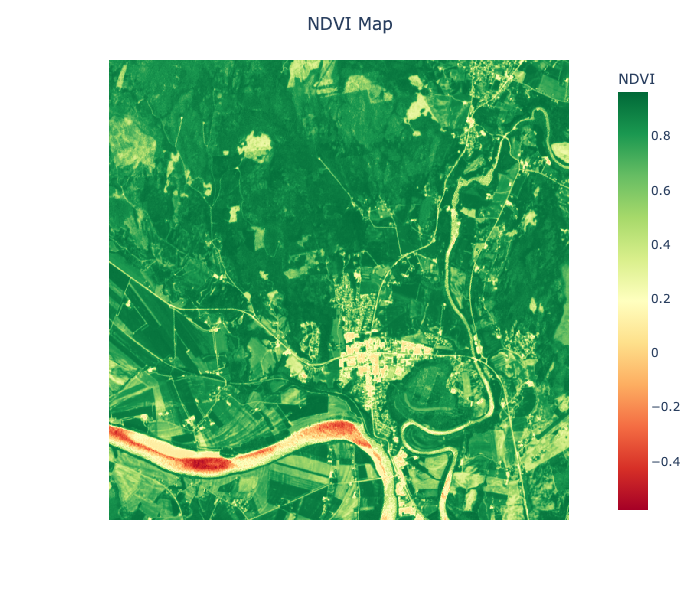

EVI: min=-0.063, max=1.070


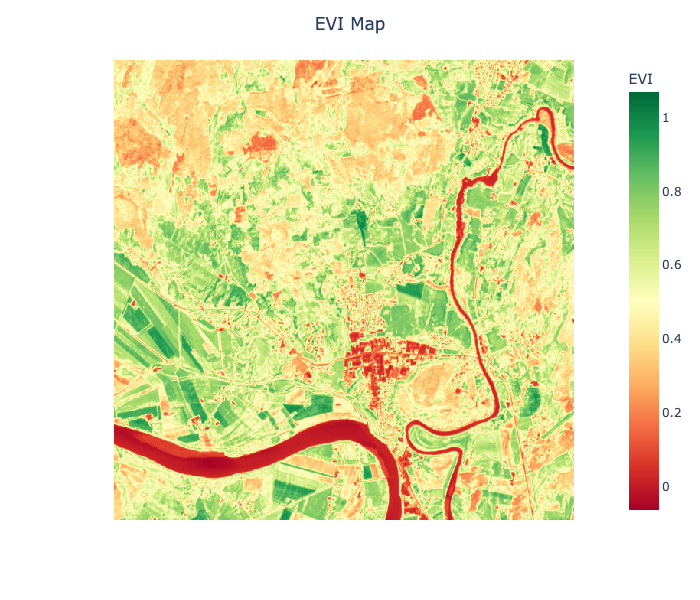

SAVI: min=-0.076, max=0.814


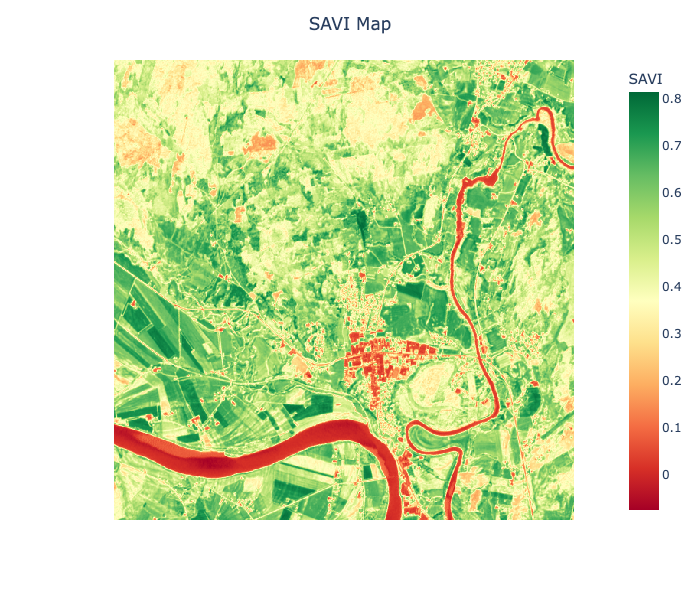

NDWI: min=-0.897, max=0.488


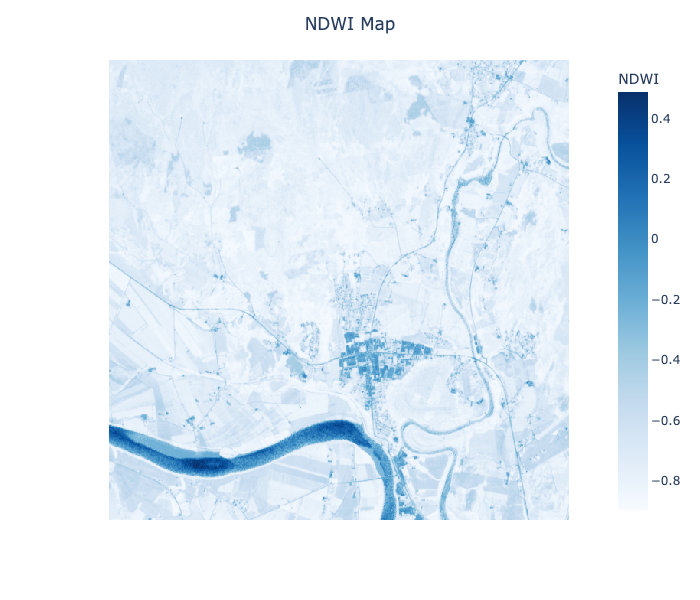

NDBI: min=-0.702, max=0.636


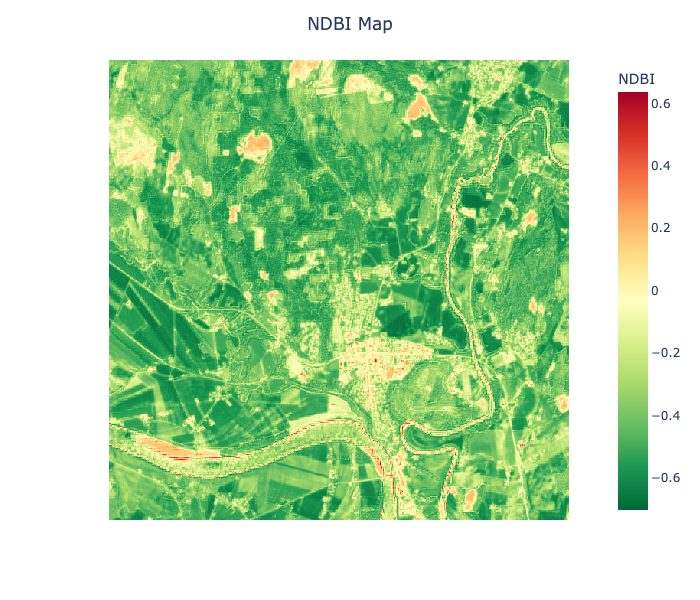

In [11]:
# Colormapping for the index maps
cmaps = {
    "NDVI": "RdYlGn",
    "EVI": "RdYlGn",
    "SAVI": "RdYlGn",
    "NDWI": "Blues",
    "NDBI": "RdYlGn_r",
}

# Plot each index as a map
for name, img in indices.items():
    print(f"{name}: min={float(img.min()):.3f}, max={float(img.max()):.3f}")
    fig = px.imshow(
        img.values,
        color_continuous_scale=cmaps[name],
        aspect="equal",
    )
    fig.update_layout(
        title={
            'text':f"{name} Map",
            'x': 0.5,
            'xanchor': 'center'
        },
        coloraxis_colorbar_title=name,
        width=700,
        height=600,
    )
    fig.update_xaxes(visible=False)
    fig.update_yaxes(visible=False)
    fig.show()

### Correlation analysis

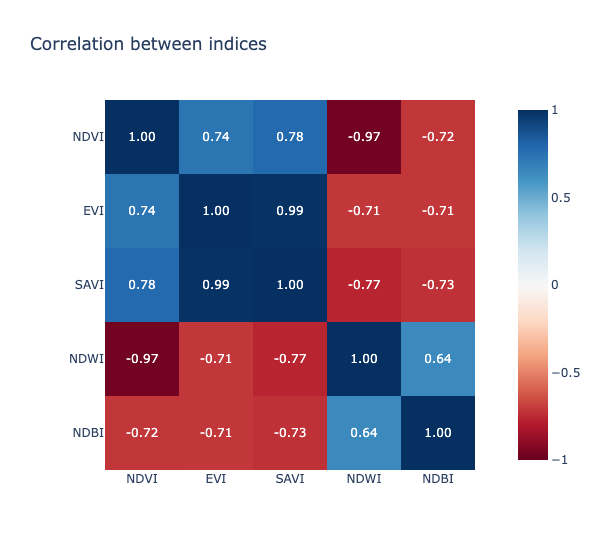

In [12]:
# One col per index, one row per pixel, without NaN pixels
index_df = pd.DataFrame(
    {name: arr.values.ravel() for name, arr in indices.items()}
).dropna()

# Correlation between all pairs of indices
corr = index_df.corr()

# Heatmap of the correlation matrix
fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu",
    zmin=-1,
    zmax=1,
    title="Correlation between indices",
)
fig.update_layout(width=600, height=550)
fig.show()

### Histograms

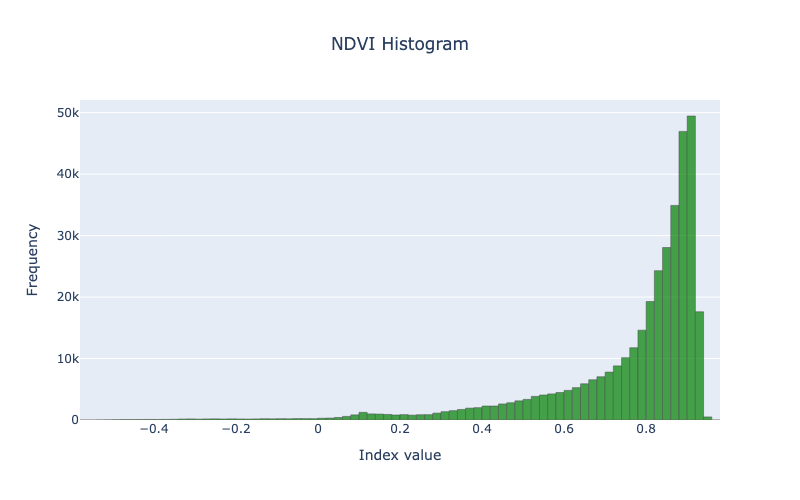

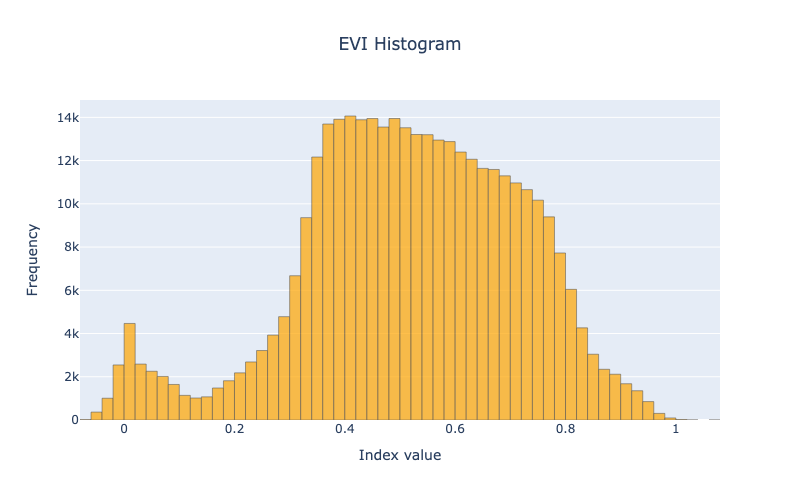

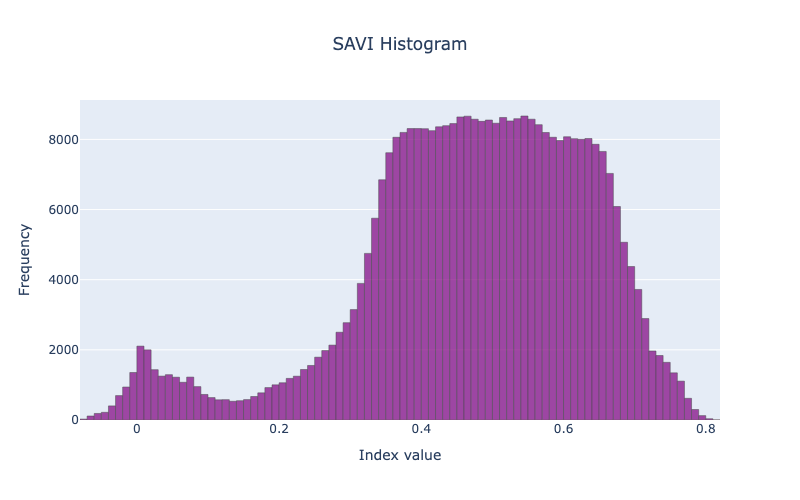

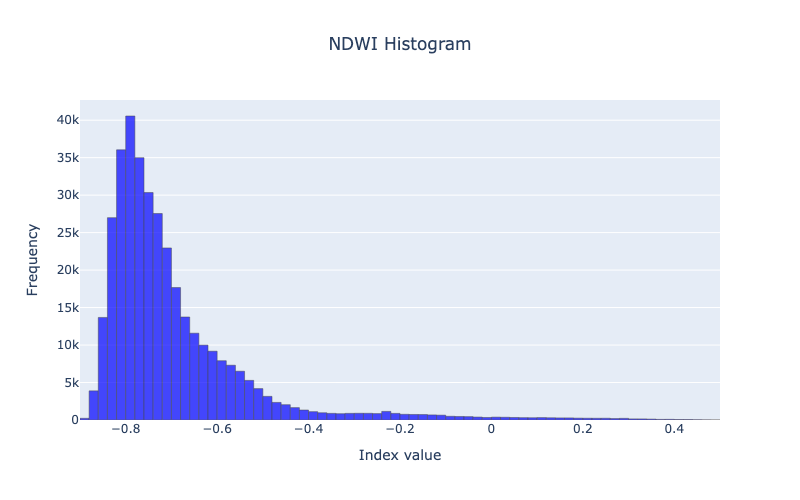

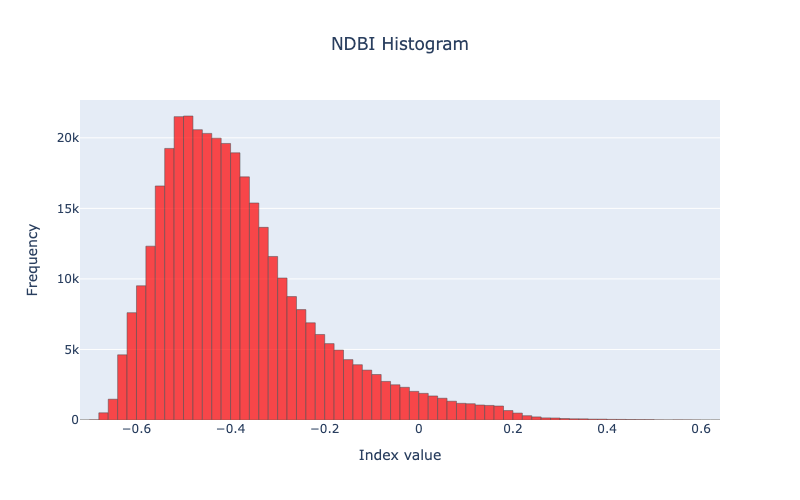

In [13]:
# One histogram (100 bins) per index
for col, color in {
    "NDVI": "green",
    "EVI": "orange",
    "SAVI": "purple",
    "NDWI": "blue",
    "NDBI": "red",
}.items():
    fig = go.Figure(
        go.Histogram(
            x=index_df[col],
            nbinsx=100,
            marker=dict(color=color, line=dict(color="black", width=0.5)),
            opacity=0.7,
        )
    )
    fig.update_layout(
        title={
            'text': f"{col} Histogram",
            'x': 0.5,
            'xanchor': 'center'
        },
        xaxis_title="Index value",
        yaxis_title="Frequency",
        width=800,
        height=500,
    )
    fig.show()

### Interpretation

**Index maps**
- **NDVI** is high almost everywhere (median 0.84, 84 % of pixels above 0.6). Forest and fields look almost the same, because NDVI saturates over dense vegetation. **EVI** and **SAVI** show much more contrast within the vegetation: the agricultural fields stand out from the surrounding forest. The Glomma and the town centre have low values in all three.
- **NDWI** separates the river clearly from everything else, which is strongly negative.
- **NDBI** only weakly highlights the town. Several bare or harvested fields have similar or higher values, a known weakness of NDBI, since both bare soil and built-up surfaces reflect more SWIR than NIR.

**Correlation**
- **EVI and SAVI (0.99)** are almost identical. Both are NIR–Red differences with an added background term.
- **NDVI and NDWI (−0.97)** are close to mirror images. Both compare NIR to a visible band (Red vs. Green), and Red and Green vary together over vegetation.
- **NDVI vs. EVI/SAVI (0.74–0.78)** is lower than expected, because NDVI saturates in dense vegetation while EVI and SAVI keep varying.
- **NDBI** is negatively correlated with the vegetation indices (≈ −0.72) and positively with NDWI (0.64). Water, roofs, roads and bare soil all have low NIR.

**Histograms**
- **NDVI** is strongly skewed with a sharp peak around 0.9 (dense, saturated vegetation) and a small tail below 0 from water.
- **EVI** and **SAVI** have a broad main peak (≈ 0.3–0.8) reflecting different vegetation types, plus a small peak near 0 from water and built-up surfaces.
- **NDWI** peaks around −0.8 (vegetation) with a long, thin tail towards positive values (the river).
- **NDBI** peaks around −0.5 with a tail towards positive values from built-up areas and bare soil.

In [14]:
client.close()